# TRABAJO FIN DE GRADO: Detección de TEA mediante sistemas de IA

#### **Estudiante**: Ángel Vilariño García
#### **Dirección**: Verónica Bolón Canedo y Brais Cancela Barizo

In [1]:
# Cargamos el archivo de datos .sav

# Librerías estándar
import os, sys, contextlib
import logging
import importlib.util
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

# Librerías de datos y numeración
import numpy as np
import pandas as pd
import pyreadstat

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from IPython.display import display, HTML, display_html

# Preprocesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Librerías de imputación
from sklearn.impute import KNNImputer

# Validación y división de datos
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

# Feature Selection
from sklearn.feature_selection import (SelectKBest, f_classif, chi2, RFE, mutual_info_classif)
from skrebate import ReliefF
import mrmr

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

# Modelos de clasificación
from sklearn.svm import LinearSVC, SVC
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

import pickle

df_sav, meta = pyreadstat.read_sav("TEA_1.sav")

df_sav.head()

,Nombre,Institución,Pais,Edad,Sexo,Altura,Peso,M_expresion,Estado_legal,Diag_secundario,...,actsococ2,act_lim3,estereotip,estereotipq,comunic,comunicq,intsoc,intsocq,habla,Diag_primario
0,G,1.0,1.0,8.0,1.0,120.0,30.0,1.0,2.0,3.0,...,1.0,1.0,30.0,4.0,18.0,1.0,34.0,3.0,0.0,1.0
1,MR,2.0,2.0,2.0,1.0,70.0,20.0,1.0,2.0,1.0,...,NaN,NaN,27.0,3.0,41.0,4.0,39.0,4.0,0.0,2.0
2,NR,2.0,2.0,5.0,2.0,95.0,25.0,2.0,2.0,3.0,...,NaN,NaN,28.0,3.0,25.0,2.0,28.0,2.0,1.0,2.0
3,AF,2.0,2.0,7.0,1.0,155.0,40.0,2.0,2.0,1.0,...,NaN,NaN,23.0,2.0,35.0,4.0,33.0,3.0,1.0,2.0
4,NL,2.0,2.0,7.0,2.0,125.0,35.0,2.0,2.0,1.0,...,NaN,NaN,28.0,3.0,39.0,4.0,42.0,4.0,1.0,2.0


In [ ]:
# Mostrar cuantos hay de cada pais y su diag_primario
df_sav[['Pais', 'Diag_primario']].value_counts()

# Eliminar Pais
# Entrenar quitando las columnas con muchos nulos

Pais  Diag_primario
2.0   1.0              86
1.0   2.0              58
2.0   2.0              53
1.0   1.0              12
Name: count, dtype: int64

### **3. PREPROCESADO**

#### 3.1. Conversión de variables numéricas a categóricas

In [2]:
# Convertimos a categóricas todas las variables menos edad, altura y peso
columnas_a_convertir = [col for col in df_sav.columns if col not in ['Edad', 'Altura', 'Peso']]

for col in columnas_a_convertir:
    df_sav[col] = df_sav[col].astype('category')

# Eliminamos la columna Nombre
df_sav = df_sav.drop(columns=['Nombre'])

columnas_categoricas = df_sav.select_dtypes(include=['category']).columns.tolist()

In [5]:
# Porcentaje de celdas nulas

porcentaje_nulo = df_sav.isnull().sum().sum() / df_sav.size * 100
print(f"Porcentaje de celdas nulas: {porcentaje_nulo:.2f}%")

Porcentaje de celdas nulas: 12.39%


#### 3.2 Imputación de valores nulos
##### 3.2.1. Imputación por moda

In [20]:
# OPCIÓN 1: IMPUTACIÓN SIMPLE POR MODA

def imputacion_moda(df):
    df_moda = df.copy()
    columnas_categoricas = df_moda.select_dtypes(include=['category']).columns.tolist()

    nulos_antes = df_moda[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos antes: {nulos_antes}")

    for col in columnas_categoricas:
        if df_moda[col].isnull().sum() > 0:
            moda = df_moda[col].mode() # Obtener la moda
            if not moda.empty:
                df_moda[col] = df_moda[col].fillna(moda[0]) # Rellenar nulos con la moda

    nulos_despues = df_moda[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos después: {nulos_despues}")

    return df_moda

df_moda = imputacion_moda(df_sav)

Nulos antes: 5594
Nulos después: 0


##### 3.2.2. Imputación por KNN

In [ ]:
# OPCIÓN 2: IMPUTACIÓN CON KNN

def imputacion_knn(df):
    df_knn = df.copy()
    columnas_categoricas = df_knn.select_dtypes(include=['category']).columns.tolist()

    # Convertir categóricas a numéricas para KNN
    df_knn_temp = df_knn.copy()
    label_encoders = {}

    for col in columnas_categoricas:
        # Para cada columna categórica, primero extraer los códigos numéricos
        # Las categorías ya tienen un orden interno que podemos usar
        df_knn_temp[col] = df_knn_temp[col].cat.codes
        # Los nulos se convierten en -1
        df_knn_temp[col] = df_knn_temp[col].replace(-1, np.nan)

    nulos_antes = df_knn_temp[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos antes: {nulos_antes}")

    # Aplicar KNN Imputer
    knn_imputer = KNNImputer(n_neighbors=5)
    datos_imputados = knn_imputer.fit_transform(df_knn_temp[columnas_categoricas])

    # Convertir de vuelta a categóricas
    for i, col in enumerate(columnas_categoricas):
        valores_imputados = datos_imputados[:, i]
        # Redondear y convertir a entero (KNN devuelve floats)
        valores_enteros = np.round(valores_imputados).astype(int)
        # Asegurarse de que los valores estén en el rango válido
        valores_enteros = np.clip(valores_enteros, 0, len(df_knn[col].cat.categories)-1)
        # Convertir de vuelta a categorías originales
        df_knn[col] = pd.Categorical.from_codes(valores_enteros, categories=df_knn[col].cat.categories)

    nulos_despues = df_knn[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos después: {nulos_despues}")

    return df_knn

df_knn = imputacion_knn(df_sav) 

Nulos antes: 5594
Nulos después: 0


##### 3.2.3. Imputación por grupos (Edad y Diagnóstico)

In [3]:
# OPCIÓN 3: IMPUTACIÓN POR GRUPOS

def imputacion_grupos(df):

    df_grupos = df.copy()
    columnas_categoricas = df_grupos.select_dtypes(include=['category']).columns.tolist()

    nulos_antes = df_grupos[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos antes: {nulos_antes}")

    moda = lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x

    # Primera pasada: imputar por grupo de edad y diagnóstico
    for col in columnas_categoricas:
        if df_grupos[col].isnull().sum() > 0:

            df_grupos[col] = df_grupos.groupby(['Edad', 'Diag_primario'], observed=False)[col].transform(moda)

    nulos_paso1 = df_grupos[columnas_categoricas].isnull().sum().sum()
    print(f"Quedan {nulos_paso1} nulos después de la 1a pasada (imputación por Edad y Diagnóstico).")

    # Segunda pasada: para los que quedaron, imputar solo por diagnóstico
    for col in columnas_categoricas:
        if df_grupos[col].isnull().sum() > 0:
            
            df_grupos[col] = df_grupos.groupby('Diag_primario', observed=False)[col].transform(moda)

    nulos_paso2 = df_grupos[columnas_categoricas].isnull().sum().sum()
    print(f"Quedan {nulos_paso2} nulos después de la 2a pasada (imputación por Diagnóstico).")

    # Tercera pasada: para los que todavía quedan, moda global
    for col in columnas_categoricas:
        if df_grupos[col].isnull().sum() > 0:
            moda_global = df_grupos[col].mode()
            if not moda_global.empty:
                df_grupos[col] = df_grupos[col].fillna(moda_global[0])

    nulos_paso3 = df_grupos[columnas_categoricas].isnull().sum().sum()
    print(f"Quedan {nulos_paso3} nulos después de la 3a pasada (imputación por moda global).")

    nulos_despues = df_grupos[columnas_categoricas].isnull().sum().sum()
    print(f"Nulos después: {nulos_despues}")

    return df_grupos

df_grupos = imputacion_grupos(df_sav)

Nulos antes: 5594
Quedan 2318 nulos después de la 1a pasada (imputación por Edad y Diagnóstico).
Quedan 0 nulos después de la 2a pasada (imputación por Diagnóstico).
Quedan 0 nulos después de la 3a pasada (imputación por moda global).
Nulos después: 0


#### 3.3. Análisis Comparativo de Calidad de Imputaciones
##### 3.3.1. Cambio en la distribución de las variables

In [23]:
# ANÁLISIS COMPARATIVO DE CALIDAD DE IMPUTACIÓN

# PRESERVACIÓN DE DISTRIBUCIONES

def calcular_cambio_distribucion(original, imputado):
    """Calcula cuánto cambió la distribución"""
    orig_dist = original.value_counts(normalize=True).sort_index()
    imp_dist = imputado.value_counts(normalize=True).sort_index()
    cambio = np.abs(orig_dist - imp_dist).mean()
    return cambio

cambios_totales = {}
for metodo, df in [('Moda', df_moda), ('KNN', df_knn), ('Grupos', df_grupos)]:
    cambios = []
    for col in columnas_categoricas:
        cambio = calcular_cambio_distribucion(df_sav[col], df[col])
        cambios.append(cambio)
    cambios_totales[metodo] = np.mean(cambios)
    print(f"{metodo}: Cambio promedio = {cambios_totales[metodo]:.4f}")

Moda: Cambio promedio = 0.0336
KNN: Cambio promedio = 0.0169
Grupos: Cambio promedio = 0.0219


##### 3.3.2. Cambio en la distribución de las variables según distancia de Jensen-Shannon

In [ ]:
# Empleamos la distancia de Jensen-Shannon porque es más adecuada para distribuciones categóricas

from scipy.spatial.distance import jensenshannon

def dist_js(original, imputado):
    p = original.value_counts(normalize=True).sort_index() # Distribución original normalizada y ordenada
    q = imputado.value_counts(normalize=True).sort_index() # Distribución imputada normalizada y ordenada
    p, q = p.align(q, fill_value=0) # Alinear índices
    return jensenshannon(p, q)

cambios_js = {}
for metodo, df in [('Moda', df_moda), ('KNN', df_knn), ('Grupos', df_grupos)]:
    cambios = []
    for col in columnas_categoricas:
        cambio = dist_js(df_sav[col], df[col])
        cambios.append(cambio)
    cambios_js[metodo] = np.mean(cambios)
    print(f"{metodo}: Distancia JS promedio = {cambios_js[metodo]:.4f}")

Moda: Distancia JS promedio = 0.0494
KNN: Distancia JS promedio = 0.0276
Grupos: Distancia JS promedio = 0.0321


**NOTA:** Se utiliza la distancia/divergencia de Jensen-Shannon para evaluar el cambio en la distribución de las variables categóricas tras la imputación de valores nulos. Este método es adecuado para comparar distribuciones de probabilidad y es especialmente útil en este caso, donde se trabaja con variables categóricas. Su fórmula se basa en la entropía de Shannon y proporciona una medida simétrica y finita: 

$JSD(P\|Q)=\frac{1}{2}D_{KL}(P\|M)+\frac{1}{2}D_{KL}(Q\|M)$

donde $M=\frac{1}{2}(P+Q)$ y $D_{KL}$ es la divergencia de Kullback-Leibler.

##### 3.3.3. Cambio en la distribución de las variables diferenciadas por cantidad de valores nulos

In [25]:
# EVALUACIÓN POR TIPO DE VARIABLE

nulos_categoricas = df_sav[columnas_categoricas].isnull().sum()

# Variables con muchos nulos vs pocos nulos
variables_muchos_nulos = nulos_categoricas[nulos_categoricas > 50].index.tolist()
variables_pocos_nulos = nulos_categoricas[nulos_categoricas <= 50].index.tolist()

print(f"Variables con muchos nulos (>50%): {len(variables_muchos_nulos)}")
print(f"Variables con pocos nulos (≤50%): {len(variables_pocos_nulos)}")

# Evaluar calidad por tipo
for tipo, vars_list in [('Muchos nulos', variables_muchos_nulos), ('Pocos nulos', variables_pocos_nulos)]:
    
    print(f"\n{tipo}:")
    for metodo, df in [('Moda', df_moda), ('KNN', df_knn), ('Grupos', df_grupos)]:
        errores = []
        for col in vars_list:
            cambio = dist_js(df_sav[col], df[col])
            errores.append(cambio)
        error_promedio = np.mean(errores)
        print(f"  {metodo}: Cambio promedio = {error_promedio:.4f}")

Variables con muchos nulos (>50%): 45
Variables con pocos nulos (≤50%): 168

Muchos nulos:
  Moda: Cambio promedio = 0.2337
  KNN: Cambio promedio = 0.1306
  Grupos: Cambio promedio = 0.1517

Pocos nulos:
  Moda: Cambio promedio = 0.0000
  KNN: Cambio promedio = 0.0000
  Grupos: Cambio promedio = 0.0000


### **4. CREACIÓN DEL PIPELINE**

#### 4.1. Carga y prueba de selección de características con E2EFS

In [26]:
# FEATURE SELECTION CON E2E-FS

ruta_repo = '/Users/mangelvilarino/Desktop/TFG/Codigo/E2E-FS'
ruta_src = os.path.join(ruta_repo, 'src')

sys.path.insert(0, ruta_repo)
sys.path.insert(0, ruta_src)

# Cargar E2EFS

ruta_archivo = os.path.join(ruta_repo, 'e2efs.py')
spec = importlib.util.spec_from_file_location("e2efs_custom", ruta_archivo)
e2efs_module = importlib.util.module_from_spec(spec)

# suprimir TODA la salida al cargar el módulo
with open(os.devnull, 'w') as f, contextlib.redirect_stdout(f), contextlib.redirect_stderr(f):
    spec.loader.exec_module(e2efs_module)

E2EFSSoft = e2efs_module.E2EFSSoft
E2EFS = e2efs_module.E2EFS
E2EFSRanking = e2efs_module.E2EFSRanking


## LOAD E2EFSSoft model
model = E2EFSSoft(n_features_to_select=20)

## OPTIONAL: Load E2EFS Model
# model = E2EFS(n_features_to_select=20)

## OPTIONAL: Load E2EFSRanking Model
# model = E2EFSRanking()


## PREPARE THE DATA
data = df_grupos.copy()

# Convertir categóricas a códigos numéricos
for col in data.select_dtypes(include=['category']).columns:
    data[col] = data[col].cat.codes

# Definir características y etiquetas
X = np.asarray(data.drop(columns=['Diag_primario']))
y = np.asarray(data['Diag_primario']).reshape(-1)

# Normalizar características

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Dividir en conjunto de entrenamiento y prueba
train_data, test_data, train_label, test_label = train_test_split(X, y, test_size=0.2, random_state=42)


## FIT THE SELECTION
# suprimir TODA la salida de fit() y fine_tune()
with open(os.devnull, 'w') as f, contextlib.redirect_stdout(f), contextlib.redirect_stderr(f):
    model.fit(
        train_data,
        train_label,
        validation_data=(test_data, test_label),
        batch_size=2,
        max_epochs=2000
    )

    ## FINETUNE THE MODEL
    model.fine_tune(
        train_data,
        train_label,
        validation_data=(test_data, test_label),
        batch_size=2,
        max_epochs=100
    )

    ## GET THE MODEL RESULTS
    metrics = model.evaluate(test_data, test_label)


## RESULTADOS
print(metrics)

## GET THE MASK
mask = model.get_mask()
print('MASK:', mask)

## GET THE RANKING
ranking = model.get_ranking()
print('RANKING:', ranking)
    
# Mostramos las características seleccionadas con el ranking obtenido
caracteristicas_seleccionadas = [data.columns[i] for i in ranking[:20]]
for i, feature in enumerate(caracteristicas_seleccionadas, 1):
    print(f"{i}. {feature}")

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │     0.976190447807312     │
│          test_ba          │    0.9791666269302368     │
│         test_loss         │    0.11461973190307617    │
└───────────────────────────┴───────────────────────────┘

{'test_loss': 0.11461973190307617, 'test_accuracy': 0.976190447807312, 'test_ba': 0.9791666269302368}
MASK: [0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.
 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 1.
 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.]
RANKING: [ 53  46 188 177 152   5  81 210  80   9 170 207 198 203 199  15 191 201
  60 200  14 193 155  54 141 205 194  25 187  28 202  59 211 148   3  52
 160  33 208 163 151 149  48 168 116  51 119  40 145 112   0  58  27  55
 174 161 

In [3]:
# Suprimir logs de TensorFlow
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Suprimir logs de PyTorch Lightning (si no se usa 'barebones')
logging.getLogger('lightning.pytorch').setLevel(logging.WARNING)

# Importar E2EFS, suprimiendo cualquier mensaje de inicialización
ruta_e2efs = '/Users/mangelvilarino/Desktop/TFG/Codigo/E2E-FS'
ruta_archivo = os.path.join(ruta_e2efs, "e2efs.py")

sys.path.insert(0, ruta_e2efs)

spec = importlib.util.spec_from_file_location("e2efs_custom", ruta_archivo)
e2efs_module = importlib.util.module_from_spec(spec)

# Usamos contextlib para suprimir la salida de la inicialización de E2EFS/TensorFlow/Lightning
with open(os.devnull, 'w') as f, contextlib.redirect_stdout(f), contextlib.redirect_stderr(f):
    spec.loader.exec_module(e2efs_module)

# Asignar la clase
E2EFSSoft = e2efs_module.E2EFSSoft

#### 4.2. Elección de selectores y modelos

In [4]:
# SELECTORES Y MODELOS

def get_selectors(k):
    return {
        "MI":     SelectKBest(lambda X, y: mutual_info_classif(X, y, random_state=42), k=k),
        "ANOVA":  SelectKBest(f_classif, k=k),
        "ReliefF": ReliefF(n_features_to_select=k),
        "mRMR":   "mRMR_marker",
        "RFE-SVM": RFE(LinearSVC(C=0.1, dual=False, max_iter=5000, random_state=42), n_features_to_select=k),
        "E2EFS":  E2EFSSoft(n_features_to_select=k)
    }

def get_modelos():
    return {
        "SVM": SVC(probability=True, random_state=42),
        "MLP": MLPClassifier((100, 50), max_iter=1000, random_state=42),
        "Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
        "RF": RandomForestClassifier(100, max_depth=10, random_state=42),
        "GB": GradientBoostingClassifier(random_state=42),
        "LR": LogisticRegression(max_iter=1000, random_state=42)
    }

#### 4.3. Elección de métricas

In [5]:
# MÉTRICAS

def metricas(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba[:,1]) if y_proba is not None else np.nan
    }

#### 4.4. Función de ejecución E2EFS

In [6]:
# Ejecución E2EFS

def run_e2efs(X, y, k, epochs):
    sel = E2EFSSoft(n_features_to_select=k)
    Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    with open(os.devnull,'w') as dn, contextlib.redirect_stdout(dn), contextlib.redirect_stderr(dn):
        sel.fit(Xtrain, ytrain, validation_data=(Xtest, ytest), batch_size=2, max_epochs=epochs[0])
        sel.fine_tune(Xtrain, ytrain, validation_data=(Xtest, ytest), batch_size=2, max_epochs=epochs[1])
    return np.array(sel.get_ranking()[:k], int)

#### 4.5. Creación del pipeline

In [7]:
# PIPELINE

PREPROCESSOR = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5, missing_values=-1)),
    ('scaler', StandardScaler())
])

def run_pipeline(df, k=20, n_splits=5, quiet=False, e2efs_epochs=(2000,100)):

    # Preparación de datos

    # Codificación de variables categóricas a códigos numéricos
    df_procesado = df.apply(lambda c: c.cat.codes if c.dtype.name=="category" else c)

    # Rellenar valores faltantes con -1
    df_procesado = df_procesado.fillna(-1)

    X_full = df_procesado.drop("Diag_primario", axis=1).values
    y_full = df_procesado["Diag_primario"].values
    feature_names = df_procesado.drop("Diag_primario", axis=1).columns.tolist()

    # Obtención de selectores y modelos
    selectors, modelos = get_selectors(k), get_modelos()

    # Cross-validation
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=42)

    resultados = []
    features_sel = {s: [] for s in selectors}

    total = n_splits * len(selectors) * len(modelos)
    with tqdm(total=total, desc="Pipeline", ncols=100, disable=quiet) as pbar:

        # Bucle CV
        for train_i, test_i in skf.split(X_full, y_full):
            
            # Datos del fold
            Xtrain_raw, Xtest_raw = X_full[train_i], X_full[test_i]
            ytrain, ytest = y_full[train_i], y_full[test_i]
            
            # 1. Imputación con KNNImputer y Estandarización
            preprocessor = clone(PREPROCESSOR) # Clona la estructura
            Xtrain = preprocessor.fit_transform(Xtrain_raw)
            Xtest = preprocessor.transform(Xtest_raw)

            for sel_name, base_sel in selectors.items():
                
                # 1. Determinar qué conjunto de datos de entrenamiento usar para el selector
                X_fit = Xtrain

                # 2. Selección de características
                if sel_name == "E2EFS":
                    idx = run_e2efs(Xtrain, ytrain, k, e2efs_epochs)
                elif sel_name == "mRMR":
                    import mrmr
                    # mRMR requiere nombres de columnas para funcionar correctamente
                    X_train_df = pd.DataFrame(X_fit, columns=feature_names)
                    y_train_ser = pd.Series(ytrain)
                    selected_cols = mrmr.mrmr_classif(X=X_train_df, y=y_train_ser, K=k, show_progress=False)
                    idx = [feature_names.index(c) for c in selected_cols]
                else:
                    sel = clone(base_sel)
                    sel.fit(X_fit, ytrain)
                    # ReliefF y otros selectores compatibles con sklearn
                    if hasattr(sel, "get_support"):
                        idx = np.where(sel.get_support())[0]
                    else:
                        # Para ReliefF de skrebate que usa top_features_
                        idx = sel.top_features_[:k]

                features_sel[sel_name].append(idx)

                # 3. Determinar qué conjunto de datos usar para el entrenamiento del clasificador
                Xtrain_f = X_fit[:, idx]
                Xtest_f = Xtest[:, idx]

                # 4. Entrenamiento y evaluación de modelos
                for mod_name, modelo in modelos.items():
                    m = clone(modelo).fit(Xtrain_f, ytrain)
                    yp = m.predict(Xtest_f)
                    yproba = m.predict_proba(Xtest_f) if hasattr(m,"predict_proba") else None
                    resultados.append({"FS": sel_name, "Modelo": mod_name, **metricas(ytest, yp, yproba)})
                    pbar.update(1)

    # ESTABILIDAD

    stability = []
    for name, idxs in features_sel.items():
        # Agrupamos todos los índices seleccionados
        all_idx = np.concatenate(idxs)
        # Obtenemos únicos y conteos
        u, ct = np.unique(all_idx, return_counts=True)
        pct = ct / len(idxs) * 100
        for i, c, p in zip(u, ct, pct):
            stability.append({
                "selector": name,
                "feature_idx": int(i),
                "feature_name": feature_names[i],
                "count": int(c),
                "pct_selected": float(p)
            })
    
    # Para cada selector, se guarda el índice de cada característica seleccionada, su nombre, cuantas veces fue seleccionada (máximo 5 veces, 1 por fold) y 
    # el porcentaje de veces que fue seleccionada

    df_res = pd.DataFrame(resultados)
    df_stab = pd.DataFrame(stability).sort_values(["selector","pct_selected"], ascending=[True,False])

    return df_res, features_sel, feature_names, df_stab

### 5. **ENTRENAMIENTO, EVALUACIÓN Y ANÁLISIS PARA K=20**

#### 5.1. Entrenamiento del pipeline

In [8]:
resultados, features, names, stability = run_pipeline(df_sav, k=20, n_splits=5, quiet=False)

Pipeline: 100%|███████████████████████████████████████████████████| 180/180 [14:40<00:00,  4.89s/it]


#### 5.2. Resultados Promedio por Modelo y Selector

In [9]:
# 1. RESULTADOS PROMEDIO POR SELECTOR Y MODELO Y TOP 10 COMBINACIONES

df_avg = resultados.groupby(['FS', 'Modelo']).agg({
    'accuracy': 'mean',
    'precision': 'mean',
    'recall': 'mean',
    'f1': 'mean',
    'roc_auc': 'mean'
}).round(4).reset_index()

display(df_avg.sort_values("f1", ascending=False))

print("\nTOP 10 MEJORES COMBINACIONES (por F1-score):")
display(df_avg.sort_values("f1", ascending=False).head(10))

,FS,Modelo,accuracy,precision,recall,f1,roc_auc
32,mRMR,MLP,0.8180,0.8294,0.8180,0.8163,0.8816
18,RFE-SVM,GB,0.8134,0.8195,0.8134,0.8118,0.8873
33,mRMR,RF,0.8086,0.8146,0.8086,0.8077,0.8821
31,mRMR,LR,0.8038,0.8108,0.8038,0.8030,0.8797
9,E2EFS,RF,0.8036,0.8153,0.8036,0.8009,0.8949
2,ANOVA,MLP,0.7990,0.8061,0.7990,0.7981,0.8794
20,RFE-SVM,MLP,0.7990,0.8081,0.7990,0.7978,0.8792
21,RFE-SVM,RF,0.7988,0.8062,0.7988,0.7975,0.8963
22,RFE-SVM,SVM,0.7990,0.8068,0.7990,0.7973,0.8794
34,mRMR,SVM,0.7942,0.8080,0.7942,0.7918,0.8771



TOP 10 MEJORES COMBINACIONES (por F1-score):


,FS,Modelo,accuracy,precision,recall,f1,roc_auc
32,mRMR,MLP,0.8180,0.8294,0.8180,0.8163,0.8816
18,RFE-SVM,GB,0.8134,0.8195,0.8134,0.8118,0.8873
33,mRMR,RF,0.8086,0.8146,0.8086,0.8077,0.8821
31,mRMR,LR,0.8038,0.8108,0.8038,0.8030,0.8797
9,E2EFS,RF,0.8036,0.8153,0.8036,0.8009,0.8949
2,ANOVA,MLP,0.7990,0.8061,0.7990,0.7981,0.8794
20,RFE-SVM,MLP,0.7990,0.8081,0.7990,0.7978,0.8792
21,RFE-SVM,RF,0.7988,0.8062,0.7988,0.7975,0.8963
22,RFE-SVM,SVM,0.7990,0.8068,0.7990,0.7973,0.8794
34,mRMR,SVM,0.7942,0.8080,0.7942,0.7918,0.8771


#### 5.3. Mejor Modelo por Métrica

In [10]:
# 2. MEJOR MODELO SEGÚN CADA MÉTRICA

mejores_modelos = {}
metricas_lista = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
for metrica in metricas_lista:
    idx_max = df_avg[metrica].idxmax()
    mejores_modelos[metrica] = df_avg.loc[idx_max]

print("MEJORES MODELOS POR MÉTRICA:")
# Muestra en un color vivo la métrica de la fila que se está mostrando
display(pd.DataFrame(mejores_modelos).T)

MEJORES MODELOS POR MÉTRICA:


,FS,Modelo,accuracy,precision,recall,f1,roc_auc
accuracy,mRMR,MLP,0.818,0.8294,0.818,0.8163,0.8816
precision,mRMR,MLP,0.818,0.8294,0.818,0.8163,0.8816
recall,mRMR,MLP,0.818,0.8294,0.818,0.8163,0.8816
f1,mRMR,MLP,0.818,0.8294,0.818,0.8163,0.8816
roc_auc,E2EFS,LR,0.7938,0.8067,0.7938,0.7907,0.9079


#### 5.4. Rendimiento Promedio de F1 Score por Selector

In [11]:
# 3. RENDIMIENTO PROMEDIO POR SELECTOR

df_por_fs = resultados.groupby("FS").agg({'accuracy':'mean', 'precision':'mean', 'recall':'mean', 'f1':'mean', 'roc_auc':'mean'}).round(4)

print("RENDIMIENTO PROMEDIO POR SELECTOR:")
display(df_por_fs.sort_values("f1", ascending=False).style.background_gradient(cmap='Blues'))

RENDIMIENTO PROMEDIO POR SELECTOR:


,accuracy,precision,recall,f1,roc_auc
FS,,,,,
RFE-SVM,0.788600,0.795700,0.788600,0.787300,0.860600
mRMR,0.784600,0.793100,0.784600,0.782800,0.844500
E2EFS,0.780400,0.788700,0.780400,0.778100,0.868500
ANOVA,0.767800,0.774500,0.767800,0.766500,0.846400
ReliefF,0.746200,0.752900,0.746200,0.744700,0.816600
MI,0.745600,0.752300,0.745600,0.743700,0.831700


#### 5.5. Rendimiento Promedio de F1 Score por Modelo

In [12]:
# 4. RENDIMIENTO PROMEDIO POR MODELO

df_por_modelo = resultados.groupby("Modelo").agg({
    'accuracy':'mean','precision':'mean','recall':'mean','f1':'mean','roc_auc':'mean'}).round(4)

print("RENDIMIENTO PROMEDIO POR MODELO:")
display(df_por_modelo.sort_values("f1", ascending=False).style.background_gradient(cmap='Blues'))

RENDIMIENTO PROMEDIO POR MODELO:


,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
RF,0.783800,0.791500,0.783800,0.782200,0.873100
MLP,0.782200,0.789400,0.782200,0.780800,0.872400
LR,0.781300,0.787900,0.781300,0.780100,0.878300
GB,0.771700,0.779900,0.771700,0.769700,0.853500
SVM,0.771800,0.781500,0.771800,0.769300,0.870600
Tree,0.722200,0.726800,0.722200,0.720900,0.720500


#### 5.6. Frecuencia de Características por Selector a nivel de Fold

In [13]:
# 5. FRECUENCIA DE FEATURES POR SELECTOR (FOLD-WISE)

feature_freq_selector = {}
# Lista para almacenar los snippets HTML de cada tabla
html_tables = []

# 1. Calcular el total de características diferentes seleccionadas por selector
# Esto suma la longitud de todas las listas de índices (idx) por fold.
total_features_selected = {
    sel_name: len(np.unique(np.concatenate(fold_lists))) 
    for sel_name, fold_lists in features.items()
}


for sel_name, fold_lists in features.items():
    all_idx = np.concatenate(fold_lists)
    # np.unique devuelve los valores únicos (índices de las features) y sus conteos
    uniq, counts = np.unique(all_idx, return_counts=True) 
    pct = counts / len(fold_lists) * 100

    df_freq = pd.DataFrame({
        "Feature": [names[i] for i in uniq],
        "count": counts,
        "% in Folds": pct
    }).sort_values("% in Folds", ascending=False)

    feature_freq_selector[sel_name] = df_freq

    # Lógica para display horizontal con gradiente y total de features
    
    # 2. Obtenemos las Top 20 features
    df_top20 = df_freq.head(20).copy()
    
    # 3. Aplicamos el gradiente de color verde a la columna "% in Folds"
    styled_table = df_top20.style.background_gradient(cmap='Greens', subset=['% in Folds'], axis=0).hide(axis='index')

    # 4. Convertimos el objeto Styler a HTML
    html_table = styled_table.to_html()
    
    # 5. Preparamos el encabezado con el total de características seleccionadas
    total_selected = total_features_selected[sel_name]
    header_text = f"Selector: {sel_name} ({total_selected} features totales)"
    
    # 6. Creamos el snippet HTML con el nuevo encabezado
    html_snippet = f"""
    <div style="display: inline-block; margin: 10px; vertical-align: top;">
        <h3 style="text-align: center;">{header_text}</h3>
        {html_table}
    </div>
    """
    html_tables.append(html_snippet)

# Mostramos todos los snippets HTML concatenados como un único bloque
display_html(''.join(html_tables), raw=True)

Feature,count,% in Folds
grav_ofens2,5,100.000000
intsocq,5,100.000000
comunicq,5,100.000000
permanece_apartado,5,100.000000
comunic,4,80.000000
diag_sec3,3,60.000000
repite_sonidos_ininteligibles,3,60.000000
hacer_cosas_repetidamente,3,60.000000
reac_condprb3,3,60.000000
frec_rep3,3,60.000000


#### 5.7. Resumen Estadístico de Estabilidad de Selección por Selector

In [14]:
# 6. RESUMEN DE ESTABILIDAD POR SELECTOR

stability_summary = stability.groupby("selector").agg({'pct_selected': ['mean', 'std', 'max', 'min']}).round(2)

stability_summary.columns = ['Media %', 'Desv.Est %', 'Max %', 'Min %']

print("RESUMEN DE ESTABILIDAD POR SELECTOR:")
display(stability_summary)

RESUMEN DE ESTABILIDAD POR SELECTOR:


,Media %,Desv.Est %,Max %,Min %
selector,,,,
ANOVA,60.61,33.35,100.0,20.0
E2EFS,40.82,27.07,100.0,20.0
MI,38.46,25.00,100.0,20.0
RFE-SVM,35.09,26.26,100.0,20.0
ReliefF,55.56,27.92,100.0,20.0
mRMR,50.00,33.89,100.0,20.0


#### 5.8. Características Consistentes entre Selectores

In [15]:
# 7. CARACTERÍSTICAS CONSISTENTES ENTRE SELECTORES (≥ 60%)

features_consensus = stability[stability['pct_selected'] >= 60].groupby('feature_name').agg({'selector':'count', 'pct_selected':'mean'
    })\
    .rename(columns={'selector':'Num_selectores', 'pct_selected':'%Estabilidad'})\
    .sort_values(['Num_selectores','%Estabilidad'], ascending=False)

# El % de estabilidad indica el porcentaje promedio de veces que la característica fue seleccionada en los folds, entre los selectores que la eligieron

display(features_consensus.head(20))

,Num_selectores,%Estabilidad
feature_name,,
cuenta_historia,6,90.000000
permanece_apartado,6,90.000000
Pais,5,96.000000
intercambia_objetos,5,88.000000
evita_contacto_ocular,5,84.000000
responde_negativamente_a_ordenes,4,90.000000
repite_sonidos_ininteligibles,4,85.000000
hacer_cosas_repetidamente,4,70.000000
Medicamentos,3,93.333333


#### 5.9. Gráficas Resumen

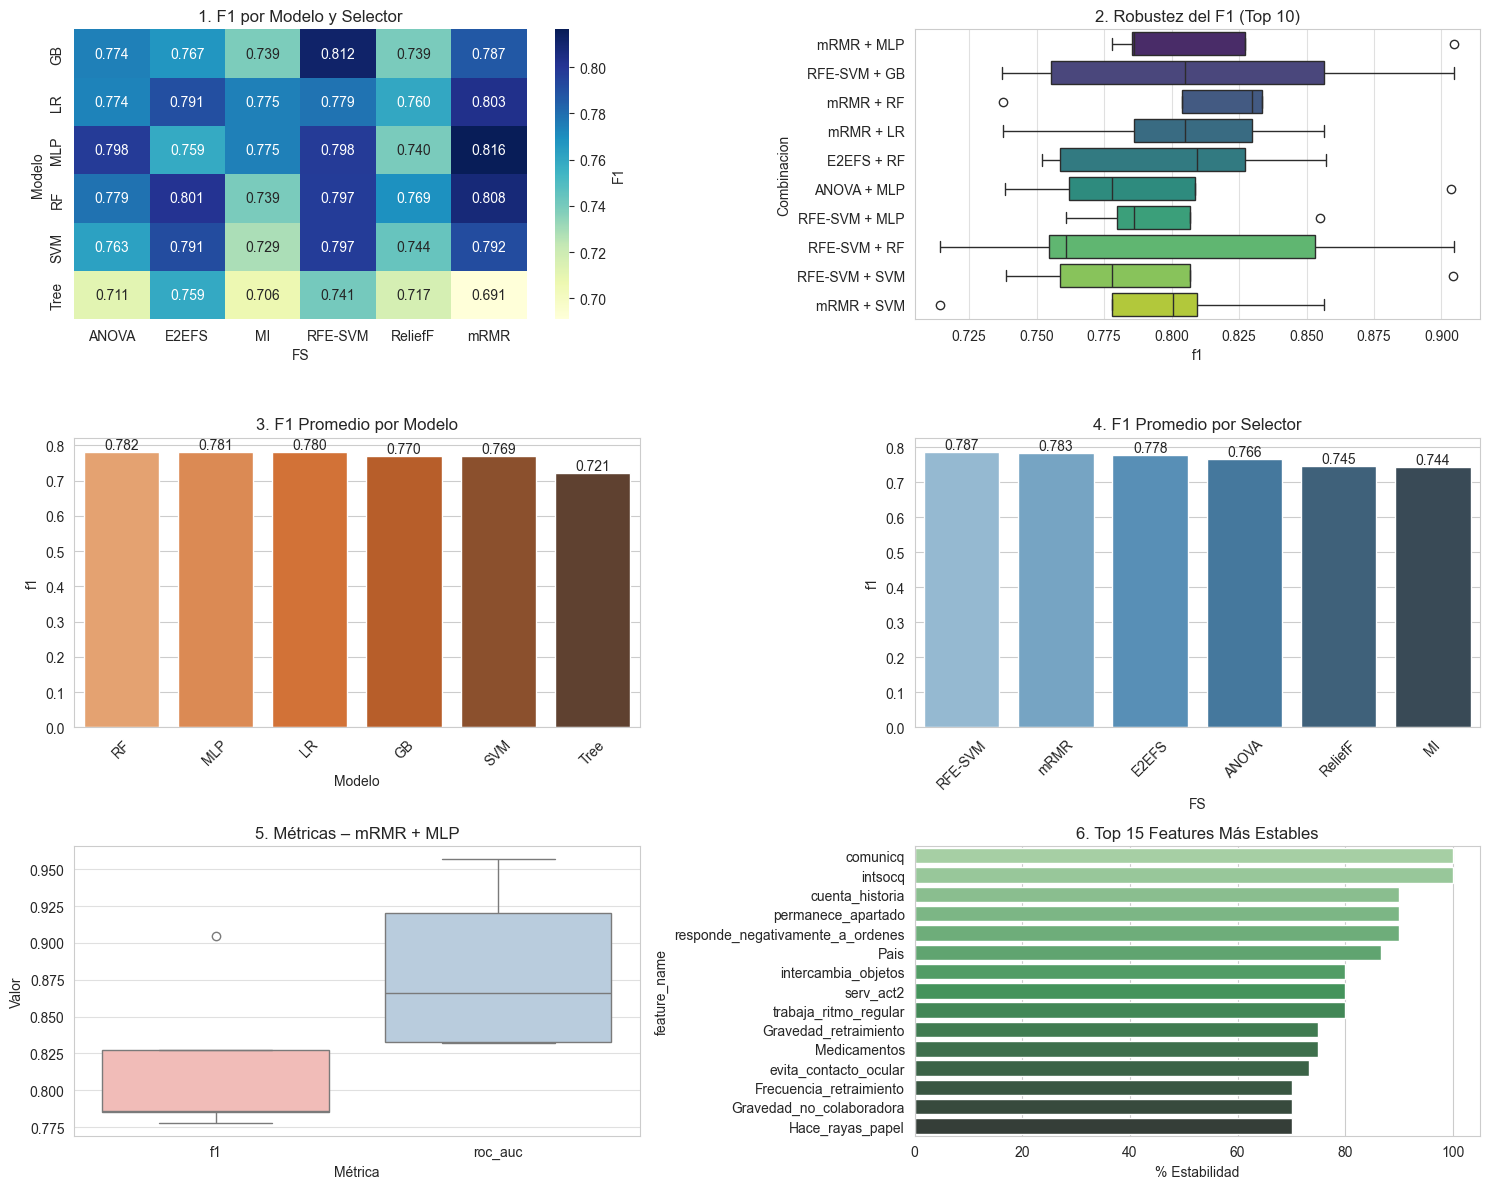

<Figure size 640x480 with 0 Axes>

In [16]:
# CONFIGURACIÓN
sns.set_style("whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.ravel()

# PREPARACIÓN
resultados["Combinacion"] = resultados["FS"] + " + " + resultados["Modelo"]

best_comb = resultados.groupby("Combinacion")["f1"].mean().idxmax()
df_best = resultados[resultados["Combinacion"] == best_comb]
df_metrics = df_best[["f1", "roc_auc"]].melt(var_name="Métrica", value_name="Valor")

# GRÁFICO 1: Heatmap F1
sns.heatmap(df_avg.pivot(index="Modelo", columns="FS", values="f1"), annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "F1"})
axes[0].set_title("1. F1 por Modelo y Selector")


# GRÁFICO 2: Boxplot Robustez
top10 = (resultados.groupby("Combinacion")["f1"].mean().nlargest(10).index)

df_top10 = resultados[resultados["Combinacion"].isin(top10)]
order = df_top10.groupby("Combinacion")["f1"].mean().sort_values(ascending=False).index

sns.boxplot(x="f1", y="Combinacion", data=df_top10,order=order, palette="viridis", ax=axes[1])
axes[1].set_title("2. Robustez del F1 (Top 10)")
axes[1].grid(True, axis="x", alpha=0.6)

# GRÁFICO 3: F1 por Modelo
df_modelo_plot = df_por_modelo.sort_values("f1", ascending=False)

sns.barplot(x=df_modelo_plot.index, y=df_modelo_plot["f1"], palette="Oranges_d", ax=axes[2])

for c in axes[2].containers:
    axes[2].bar_label(c, fmt="%.3f")

axes[2].set_title("3. F1 Promedio por Modelo")
axes[2].tick_params(axis="x", rotation=45)

# GRÁFICO 4: F1 por Selector
df_fs_plot = df_por_fs.sort_values("f1", ascending=False)

sns.barplot(x=df_fs_plot.index, y=df_fs_plot["f1"], palette="Blues_d", ax=axes[3])

for c in axes[3].containers:
    axes[3].bar_label(c, fmt="%.3f")

axes[3].set_title("4. F1 Promedio por Selector")
axes[3].tick_params(axis="x", rotation=45)

# GRÁFICO 5: Métricas mejor combinación
sns.boxplot(x="Métrica", y="Valor", data=df_metrics, palette="Pastel1", ax=axes[4])

axes[4].set_title(f"5. Métricas – {best_comb}")
axes[4].grid(True, axis="y", alpha=0.6)

# GRÁFICO 6: Features más estables
top15 = (stability.groupby("feature_name")["pct_selected"].mean().nlargest(15))

sns.barplot(x=top15.values, y=top15.index, palette="Greens_d", orient="h", ax=axes[5])

axes[5].set_title("6. Top 15 Features Más Estables")
axes[5].set_xlabel("% Estabilidad")

plt.tight_layout()
plt.show()

# Guardar gráfica en grafcias_cap5

plt.savefig("graficas_cap5/graficas_resumen_k20.png")

### 6. **ENTRENAMIENTO, EVALUACIÓN Y ANÁLISIS PARA DIFERENTES VALORES DE K**

#### 6.1. Creación del pipeline para diferentes valores de K

In [8]:
# ANÁLISIS VARIANDO K

def run_k_analysis(df, k_values=[5, 10, 20, 30, 50], n_splits=5, quiet=True, e2efs_epochs=(2000,100)):
    resultados_k = {}
    for k in k_values:
        print(f"\nAnálisis con k={k}")
        resultados, features, names, stability = run_pipeline(
            df, k=k, n_splits=n_splits, quiet=quiet, e2efs_epochs=e2efs_epochs
        )
        resultados_k[k] = {
            "resultados": resultados,
            "features": features,
            "names": names,
            "stability": stability
        }
    return resultados_k

#### 6.2. Entrenamiento del pipeline para diferentes valores de K

In [9]:
resultados_k = run_k_analysis(df_sav)


Análisis con k=5

Análisis con k=10

Análisis con k=20

Análisis con k=30

Análisis con k=50


In [ ]:
# Guardamos el diccionario completo con toda la estructura de folds y listas
with open('resultados_completos_k.pkl', 'wb') as f:
    pickle.dump(resultados_k, f)

### 7. **ENTRENAMIENTO, EVALUACIÓN Y ANÁLISIS PARA DIFERENTES VALORES DE K (SIN VARIABLES CON MUCHOS NULOS)**

In [11]:
# 1. ELIMINACIÓN DE COLUMNAS CON MUCHOS NULOS

umbral_nulos = 0.5
proporcion_nulos = df_sav.isnull().mean()
cols_a_eliminar = proporcion_nulos[proporcion_nulos > umbral_nulos].index.tolist()

print(f"Total de columnas antes: {df_sav.shape[1]}")
print(f"Columnas eliminadas (>{umbral_nulos*100}% nulos): {len(cols_a_eliminar)}")
print(f"Lista de eliminadas: {cols_a_eliminar}")

# Creamos el dataframe limpio para el entrenamiento
df_sin_nulos = df_sav.drop(columns=cols_a_eliminar)

# Actualizamos la lista de columnas categóricas para que no de error
columnas_categoricas = [col for col in df_sin_nulos.columns if df_sin_nulos[col].dtype.name == 'category']
print(f"Total de columnas después: {df_sin_nulos.shape[1]}")

Total de columnas antes: 216
Columnas eliminadas (>50.0% nulos): 25
Lista de eliminadas: ['Frec_autoles3', 'grav_autoles3', 'grav_autoles2', 'frec_hetragrs3', 'grav_hetragr2', 'frec_destr3', 'frec_destr2', 'frec_disr3', 'grav_disr3', 'grav_disr2', 'frec_rep3', 'frec_ofens4', 'grav_ofens2', 'frec_retrm3', 'grav_retrm3', 'Frec_nocol3', 'Frec_nocol2', 'grav_nocol2', 'reac_condprb3', 'serv_act2', 'serv_apoyact3', 'act_sococ3', 'actsococ2', 'act_lim3', 'habla']
Total de columnas después: 191


In [12]:
# 2. ENTRENAMIENTO PARA VARIOS VALORES DE K

# Usamos el dataframe filtrado en la celda anterior
resultados_k = run_k_analysis(df_sin_nulos, n_splits=5)


Análisis con k=5

Análisis con k=10

Análisis con k=20

Análisis con k=30

Análisis con k=50


In [13]:
with open('resultados_sin_nulos_k.pkl', 'wb') as f:
    pickle.dump(resultados_k, f)

### 7.1 Entrenamiento sin variable País a mayores

In [14]:
print(f"--- PREPARACIÓN DEL DATASET FILTRADO ---")
print(f"Total de columnas originales: {df_sav.shape[1]}")
print(f"Variables a eliminar (Nulos > 50% o 'Pais'): {len(cols_a_eliminar) + 1}")
print(f"Lista de variables descartadas: {cols_a_eliminar, 'Pais'}")

# 3. Creación del DataFrame limpio
df_sin_nulos_final = df_sin_nulos.drop(columns='Pais')
print(f"Total de columnas resultantes para el entrenamiento: {df_sin_nulos_final.shape[1]}")

--- PREPARACIÓN DEL DATASET FILTRADO ---
Total de columnas originales: 216
Variables a eliminar (Nulos > 50% o 'Pais'): 26
Lista de variables descartadas: (['Frec_autoles3', 'grav_autoles3', 'grav_autoles2', 'frec_hetragrs3', 'grav_hetragr2', 'frec_destr3', 'frec_destr2', 'frec_disr3', 'grav_disr3', 'grav_disr2', 'frec_rep3', 'frec_ofens4', 'grav_ofens2', 'frec_retrm3', 'grav_retrm3', 'Frec_nocol3', 'Frec_nocol2', 'grav_nocol2', 'reac_condprb3', 'serv_act2', 'serv_apoyact3', 'act_sococ3', 'actsococ2', 'act_lim3', 'habla'], 'Pais')
Total de columnas resultantes para el entrenamiento: 190


In [ ]:
# ENTRENAMIENTO FINAL: ESTRATEGIA SIN NULOS Y SIN VARIABLE 'PAIS'

# Ejecución del pipeline para varios valores de K (5, 10, 20, 30, 50)
# Los resultados se guardarán con la misma estructura que el experimento completo
resultados_sin_nulos_pais_k = run_k_analysis(df_sin_nulos_final, n_splits=5)

# 5. Guardado de resultados mediante Pickle
with open('resultados_sin_nulos_pais_k.pkl', 'wb') as f:
    pickle.dump(resultados_sin_nulos_pais_k, f)

print("\nEntrenamiento finalizado y resultados guardados en 'resultados_sin_nulos_pais_k.pkl'")

--- PREPARACIÓN DEL DATASET FILTRADO ---
Total de columnas originales: 216
Variables a eliminar (Nulos > 50% o 'Pais'): 26
Lista de variables descartadas: ['Frec_autoles3', 'grav_autoles3', 'grav_autoles2', 'frec_hetragrs3', 'grav_hetragr2', 'frec_destr3', 'frec_destr2', 'frec_disr3', 'grav_disr3', 'grav_disr2', 'frec_rep3', 'frec_ofens4', 'grav_ofens2', 'frec_retrm3', 'grav_retrm3', 'Frec_nocol3', 'Frec_nocol2', 'grav_nocol2', 'reac_condprb3', 'serv_act2', 'serv_apoyact3', 'act_sococ3', 'actsococ2', 'act_lim3', 'habla', 'Pais']
Total de columnas resultantes para el entrenamiento: 190

Análisis con k=5

Análisis con k=10

Análisis con k=20

Análisis con k=30

Análisis con k=50

 Entrenamiento finalizado y resultados guardados en 'resultados_sin_nulos_pais_k.pkl'


### 7.2 Entrenamiento sin variable País y sin variables con muchos nulos, sin selección de características

In [ ]:
# ENTRENAMIENTO SIN SELECCIÓN DE CARACTERÍSTICAS Y SIN LA VARIABLE 'PAIS' NI LAS COLUMNAS CON MUCHOS NULOS

# 1. Codificación y preparación (siguiendo la lógica de tu preprocesamiento)
df_proc_no_fs = df_sin_nulos_final.apply(lambda c: c.cat.codes if c.dtype.name=="category" else c)
df_proc_no_fs = df_proc_no_fs.fillna(-1)

X_full_no_fs = df_proc_no_fs.drop("Diag_primario", axis=1).values
y_full_no_fs = df_proc_no_fs["Diag_primario"].values

# 2. Bucle de entrenamiento con Validación Cruzada (CV=5)
# No usamos selectores, pasamos X completo a los modelos
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos_dict = get_modelos()
resultados_sin_fs_list = []

print("Entrenando modelos en el dataset completo...")

for train_i, test_i in skf.split(X_full_no_fs, y_full_no_fs):
    Xtrain_raw, Xtest_raw = X_full_no_fs[train_i], X_full_no_fs[test_i]
    ytrain, ytest = y_full_no_fs[train_i], y_full_no_fs[test_i]
    
    # Preprocesamiento (Imputación y Escalado)
    preprocessor = clone(PREPROCESSOR)
    Xtrain_scaled = preprocessor.fit_transform(Xtrain_raw)
    Xtest_scaled = preprocessor.transform(Xtest_raw)
    
    for mod_name, modelo in modelos_dict.items():
        m = clone(modelo).fit(Xtrain_scaled, ytrain)
        yp = m.predict(Xtest_scaled)
        yproba = m.predict_proba(Xtest_scaled) if hasattr(m, "predict_proba") else None
        
        # Calculamos métricas y añadimos información del modelo
        res_fold = metricas(ytest, yp, yproba)
        res_fold['Modelo'] = mod_name
        resultados_sin_fs_list.append(res_fold)

# 3. Creación de la tabla de resultados finales (Promedio de los folds)
df_resultados_sin_fs = pd.DataFrame(resultados_sin_fs_list).groupby('Modelo').mean().reset_index()

# 4. Guardado y Visualización
print("\nTABLA DE RENDIMIENTO SIN SELECCIÓN DE CARACTERÍSTICAS\n(Y SIN 'PAIS' NI COLUMNAS CON MUCHOS NULOS'): 5-FOLD CV")
display(df_resultados_sin_fs.sort_values(by='f1', ascending=False).style.background_gradient(cmap='Blues'))  

Entrenando modelos en el dataset completo...

TABLA DE RENDIMIENTO SIN SELECCIÓN DE CARACTERÍSTICAS
(Y SIN 'PAIS' NI COLUMNAS CON MUCHOS NULOS'): 5-FOLD CV


,Modelo,accuracy,precision,recall,f1,roc_auc
0,GB,0.822648,0.830752,0.822648,0.820926,0.891545
3,RF,0.808479,0.816132,0.808479,0.806275,0.887464
2,MLP,0.799071,0.814154,0.799071,0.796375,0.870404
4,SVM,0.798839,0.812665,0.798839,0.794179,0.884566
1,LR,0.784204,0.798761,0.784204,0.781592,0.839643
5,Tree,0.731707,0.735017,0.731707,0.730712,0.730366


In [25]:
with open('resultados/resultados_sin_pais_no_fs.pkl', 'wb') as f:
    pickle.dump(df_resultados_sin_fs, f)

print(f"\n Resultados guardados en 'resultados/resultados_sin_pais_no_fs.pkl'")


 Resultados guardados en 'resultados/resultados_sin_pais_no_fs.pkl'
